<a href="https://colab.research.google.com/github/raflialdiansyah046-bot/Tugas_text_processing_comment_youtube/blob/main/tugas_text_processing_raditya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

pre processing

In [ ]:
import requests
import json
import pandas as pd
import re
import nltk

In [ ]:
api_key = "apa yh"

video_id = "rR0A9xZlXqQ"
max_result = 100

url = f"https://www.googleapis.com/youtube/v3/commentThreads"

params = {
    "part": "snippet",
    "videoId": video_id,
    "maxResults": max_result,
    "key": api_key
}

response = requests.get(url, params=params)

print(response.status_code)

data = response.json()

200


In [ ]:
comments = []

for item in data["items"]:
    comment = item["snippet"]["topLevelComment"]["snippet"]["textDisplay"]
    comments.append(comment)

print("Jumlah komentar:", len(comments))

for comment in comments[:1000]:
    print(comment)

Jumlah komentar: 100
Payah ngga ada dabunya😮😮😮
Daging apa sih.
bang traktir makan dong
Hidup MBG
bagi lah bang boykun
🎉 fix daging terlezat &amp; terharam adalah daging babi .... lezatnyooo
Apa itu daging belly
Bang harga 1 daging nya berapa
nampak macam sedap
👍
Setara kalo makan sama bg nasinya 2liter😅
Selasa, 6 Oktober 2026 jam 13.46
Cek, promo,
Orang kaya bilek,&quot;anjir daging premium pake nasi
Cara iris bawang nya aja masih bingung dan lama tapi lagak nya udah kayak sef tapi kalau kamu itu sef tai nya anjing
Did he just said bismillah??
sekitar 15 biji aja
nyam nyam
Kok bisa ya? Lambungnya segede apa dia teh??
lanjut mang
😮
Assalamualaikum bang ,,,coba review daging unta utuh bang ...
itu daging sapi bang?
Babah
Jujur bang, w kira daging b2 sekilas
aku nak satu
Banf makan salmon 1 ton
Makan banyak tapi yg besar hanya bibir
Kelihatanya seperti dagin Baby
Where  you  come  from ?  And what your  mission above  study ?  Thank  you  guys .
Selamat Malam Saya Yayuk  mengajukan pertan

In [ ]:
df = pd.DataFrame({
    "text": comments
})

df.head()

,text
0,Payah ngga ada dabunya😮😮😮
1,Daging apa sih.
2,bang traktir makan dong
3,Hidup MBG
4,bagi lah bang boykun


In [ ]:
!pip install --upgrade git+https://github.com/ariaghora/mpstemmer.git
!pip install Levenshtein

  Cloning https://github.com/ariaghora/mpstemmer.git to /tmp/pip-req-build-rk2psn_4
  Running command git clone --filter=blob:none --quiet https://github.com/ariaghora/mpstemmer.git /tmp/pip-req-build-rk2psn_4
  Resolved https://github.com/ariaghora/mpstemmer.git to commit 25a5fd923af163a7eac3a5ec976984156ca8fa8b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for mpstemmer: filename=mpstemmer-0.1.0-py3-none-any.whl size=99831 sha256=24df1b83426f0bdfa5619d00faacde6e82b2869ccdc4b3986260f92e647a2a9b
  Stored in directory: /tmp/pip-ephem-wheel-cache-_lz7g6lx/wheels/d0/b9/fd/dba0c7d44e5338db51da6ffcbe96db4326db3996a403f5ced1
Successfully built mpstemmer
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 4.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [Levenshtein]


In [ ]:
import string
from nltk.corpus import stopwords
from mpstemmer import MPStemmer

stemmer = MPStemmer()
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
def remove_html(text):
  html_pattern = re.compile('<.*?>')
  return html_pattern.sub(r'', text)

df['rm_html'] = df['text'].apply(remove_html)
df[['text', 'rm_html']].head()

,text,rm_html
0,Payah ngga ada dabunya😮😮😮,Payah ngga ada dabunya😮😮😮
1,Daging apa sih.,Daging apa sih.
2,bang traktir makan dong,bang traktir makan dong
3,Hidup MBG,Hidup MBG
4,bagi lah bang boykun,bagi lah bang boykun


In [ ]:
def remove_html(text):
    html_pattern = re.compile('<.*?>')
    return html_pattern.sub(r'', text)

df['rm_html'] = df['text'].apply(remove_html)

df[['text', 'rm_html']].head()

,text,rm_html
0,bang traktir makan dong,bang traktir makan dong
1,Hidup MBG,Hidup MBG
2,bagi lah bang boykun,bagi lah bang boykun
3,🎉 fix daging terlezat &amp; terharam adalah da...,🎉 fix daging terlezat &amp; terharam adalah da...
4,Apa itu daging belly,Apa itu daging belly


In [ ]:
def remove_hashtag(text):
    return re.sub(r'#\w+', '', text)

df['rm_hashtag'] = df['rm_html'].apply(remove_hashtag)

df[['rm_html', 'rm_hashtag']].head()

,rm_html,rm_hashtag
0,Payah ngga ada dabunya😮😮😮,Payah ngga ada dabunya😮😮😮
1,Daging apa sih.,Daging apa sih.
2,bang traktir makan dong,bang traktir makan dong
3,Hidup MBG,Hidup MBG
4,bagi lah bang boykun,bagi lah bang boykun


In [ ]:
df['lower_case'] = df['rm_hashtag'].str.lower()

df[['rm_hashtag', 'lower_case']].head()

,rm_hashtag,lower_case
0,Payah ngga ada dabunya😮😮😮,payah ngga ada dabunya😮😮😮
1,Daging apa sih.,daging apa sih.
2,bang traktir makan dong,bang traktir makan dong
3,Hidup MBG,hidup mbg
4,bagi lah bang boykun,bagi lah bang boykun


In [ ]:
def remove_rls(text):
    text = re.sub(r'https?://\S+', '', str(text))
    text = re.sub(r'http\S+', '', str(text))
    text = re.sub(r'www\S+', '', str(text))
    text = re.sub(r'\S+@\S+', '', str(text))
    return text

df['rm_url'] = df['lower_case'].apply(remove_rls)

df[['lower_case', 'rm_url']].head()

,lower_case,rm_url
0,payah ngga ada dabunya😮😮😮,payah ngga ada dabunya😮😮😮
1,daging apa sih.,daging apa sih.
2,bang traktir makan dong,bang traktir makan dong
3,hidup mbg,hidup mbg
4,bagi lah bang boykun,bagi lah bang boykun


In [ ]:
def remove_punctuation_list(text):

    # Remove emoticon
    text = re.sub(r'(:\)|:-\)|:D|:-D|;\)|;-\))', '', text)
    text = re.sub(r'(:\(|:-\()', '', text)
    text = re.sub(r'(:v|:-v)', '', text)

    # Remove punctuation
    text = re.sub(r'[!"#$%&\'()*+,\-./:;<=>?@\[\]^_`{|}~]', ' ', text)

    # Rapikan spasi
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['rm_punc'] = df['rm_url'].apply(remove_punctuation_list)

df[['rm_url', 'rm_punc']].head()

,rm_url,rm_punc
0,payah ngga ada dabunya😮😮😮,payah ngga ada dabunya😮😮😮
1,daging apa sih.,daging apa sih
2,bang traktir makan dong,bang traktir makan dong
3,hidup mbg,hidup mbg
4,bagi lah bang boykun,bagi lah bang boykun


In [ ]:
df['stem'] = df['rm_punc'].apply(
    lambda x: stemmer.stem_kalimat(x) if isinstance(x, str) else ''
)

df[['rm_punc', 'stem']].head()

,rm_punc,stem
0,payah ngga ada dabunya😮😮😮,payah tidak ada dabunya😮😮😮
1,daging apa sih,daging apa sih
2,bang traktir makan dong,bang traktir makan dong
3,hidup mbg,hidup mbg
4,bagi lah bang boykun,bagi lah bang boykun


In [ ]:
sw = set(stopwords.words('indonesian'))

def remove_stopwords(text):
    return " ".join(
        [word for word in str(text).split() if word not in sw]
    )

df['rm_stopwords'] = df['stem'].apply(remove_stopwords)

df[['stem', 'rm_stopwords']].head()

,stem,rm_stopwords
0,payah tidak ada dabunya😮😮😮,payah dabunya😮😮😮
1,daging apa sih,daging sih
2,bang traktir makan dong,bang traktir makan
3,hidup mbg,hidup mbg
4,bagi lah bang boykun,bang boykun


In [ ]:
df["prepro"] = df['rm_stopwords']

In [ ]:
df[["text", "prepro"]].head(1000)

,text,prepro
0,Payah ngga ada dabunya😮😮😮,payah dabunya😮😮😮
1,Daging apa sih.,daging sih
2,bang traktir makan dong,bang traktir makan
3,Hidup MBG,hidup mbg
4,bagi lah bang boykun,bang boykun
...,...,...
95,Itu daging babi,daging babi
96,67!,67
97,Mati lu makan kecubung,mati lu makan kecubung
98,❤❤🎉,❤❤🎉


In [ ]:
df.to_csv(
    "Hasil_preprocessing.csv",
    index=False,
    encoding="utf-8-sig"
)

feature engineering

In [ ]:
!pip -q install gensim
!pip -q install umap-learn plotly

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import nltk
from nltk import word_tokenize
from gensim.models import Word2Vec
from gensim.models import FastText
from umap import UMAP
import plotly.express as px

In [ ]:
df_fe = df[['text', 'prepro']].copy()

df_fe['prepro'] = df_fe['prepro'].fillna('').astype(str).str.strip()
df_fe = df_fe[df_fe['prepro'] != ''].reset_index(drop=True)

df_pre = df_fe['prepro']

print("Jumlah komentar:", len(df_pre))
df_fe[['text', 'prepro']].head()

Jumlah komentar: 97


,text,prepro
0,Payah ngga ada dabunya😮😮😮,payah dabunya😮😮😮
1,Daging apa sih.,daging sih
2,bang traktir makan dong,bang traktir makan
3,Hidup MBG,hidup mbg
4,bagi lah bang boykun,bang boykun


In [ ]:
vectorizer_binary = CountVectorizer(binary=True)

X_binary = vectorizer_binary.fit_transform(df_pre)

df_onehot = pd.DataFrame(
    X_binary.toarray(),
    columns=vectorizer_binary.get_feature_names_out()
)

print("Ukuran matriks:", X_binary.shape)
display(df_onehot.iloc[:5, :15])

Ukuran matriks: (97, 245)


,09,11,13,15,17,2021,2026,2liter,38,43,46,51,54,67,abang
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
vectorizer_count = CountVectorizer()

X_count = vectorizer_count.fit_transform(df_pre)

df_count = pd.DataFrame(
    X_count.toarray(),
    columns=vectorizer_count.get_feature_names_out()
)

print("Ukuran matriks:", X_count.shape)
display(df_count.iloc[:5, :15])

Ukuran matriks: (97, 245)


,09,11,13,15,17,2021,2026,2liter,38,43,46,51,54,67,abang
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
vectorizer_tfidf = TfidfVectorizer()

X_tfidf = vectorizer_tfidf.fit_transform(df_pre)

df_tfidf = pd.DataFrame(
    X_tfidf.toarray(),
    columns=vectorizer_tfidf.get_feature_names_out()
)

print("Ukuran matriks:", X_tfidf.shape)
display(df_tfidf.iloc[:5, :15])

Ukuran matriks: (97, 245)


,09,11,13,15,17,2021,2026,2liter,38,43,46,51,54,67,abang
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')

sentences = [
    word_tokenize(tweet.lower())
    for tweet in df_pre
]

model_w2v = Word2Vec(
    sentences,
    min_count=1,
    vector_size=100,
    window=5,
    sg=0,
    epochs=10
)

print("10 kata pertama:")
print(model_w2v.wv.index_to_key[:10])

print("Ukuran vektor kata:", model_w2v.wv.vectors.shape)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


10 kata pertama:
['daging', 'bang', 'tonton', '2026', 'babi', 'makan', 'nya', 'puasa', 'enak', 'gue']
Ukuran vektor kata: (261, 100)


In [ ]:
def get_document_vector(tokens, model):
    valid_vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(valid_vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(valid_vectors, axis=0)


X_w2v = np.array([
    get_document_vector(doc, model_w2v)
    for doc in sentences
])

df_w2v = pd.DataFrame(
    X_w2v,
    columns=[f'w2v_{i+1}' for i in range(100)]
)

print("Ukuran fitur dokumen:", df_w2v.shape)
display(df_w2v.head())

Ukuran fitur dokumen: (97, 100)


,w2v_1,w2v_2,w2v_3,w2v_4,w2v_5,w2v_6,w2v_7,w2v_8,w2v_9,w2v_10,...,w2v_91,w2v_92,w2v_93,w2v_94,w2v_95,w2v_96,w2v_97,w2v_98,w2v_99,w2v_100
0,-0.002147,-0.002923,-0.007833,0.000742,0.003238,-0.001343,-0.008130,-0.007019,-0.000667,0.004292,...,0.001248,-0.000957,-0.002966,-0.005253,-0.000329,0.004440,0.004482,-0.008181,0.001334,-0.003629
1,0.001411,-0.003092,0.007097,0.002419,-0.008171,-0.004751,0.005735,0.005257,-0.000695,0.002726,...,-0.001293,-0.002432,0.006279,-0.001441,0.007523,0.007637,-0.001062,-0.007263,0.004845,0.004446
2,-0.002781,0.004066,0.001070,-0.003632,0.001146,-0.000417,0.001795,0.002857,-0.005906,-0.007721,...,0.002428,0.003691,-0.004906,-0.004996,-0.000268,-0.000025,-0.000759,-0.003245,-0.003530,0.001593
3,-0.007207,-0.004500,-0.008619,-0.007384,0.007424,-0.004178,0.006318,-0.005060,0.000808,-0.004481,...,-0.004190,-0.002673,-0.007708,-0.007065,-0.004240,-0.000586,-0.001527,-0.005652,0.005769,0.006052
4,-0.002904,0.004902,0.004995,0.004390,0.002419,-0.004706,0.000982,0.006850,0.003453,0.000121,...,0.001241,-0.000064,0.000363,-0.008859,-0.003842,0.002469,0.001457,0.003325,-0.007439,-0.002480


In [ ]:
model_fasttext = FastText(
    sentences,
    min_count=1,
    vector_size=100,
    window=5,
    min_n=3,
    max_n=6,
    sg=1,
    epochs=10
)

print("10 kata pertama:")
print(model_fasttext.wv.index_to_key[:10])

print("Ukuran vektor kata:", model_fasttext.wv.vectors.shape)

10 kata pertama:
['daging', 'bang', 'tonton', '2026', 'babi', 'makan', 'nya', 'puasa', 'enak', 'gue']
Ukuran vektor kata: (261, 100)


In [ ]:
X_fasttext = np.array([
    get_document_vector(doc, model_fasttext)
    for doc in sentences
])

df_fasttext = pd.DataFrame(
    X_fasttext,
    columns=[f'fasttext_{i+1}' for i in range(100)]
)

print("Ukuran fitur dokumen:", df_fasttext.shape)
display(df_fasttext.head())

Ukuran fitur dokumen: (97, 100)


,fasttext_1,fasttext_2,fasttext_3,fasttext_4,fasttext_5,fasttext_6,fasttext_7,fasttext_8,fasttext_9,fasttext_10,...,fasttext_91,fasttext_92,fasttext_93,fasttext_94,fasttext_95,fasttext_96,fasttext_97,fasttext_98,fasttext_99,fasttext_100
0,-0.001525,-0.001411,-0.000755,0.000748,0.000321,0.000699,-0.001141,0.000002,-0.002090,0.000117,...,0.001247,0.000296,-0.000362,-0.002586,-0.000565,0.001008,0.000710,-0.000045,0.001225,0.002082
1,-0.000238,0.001643,-0.000231,0.001535,-0.000040,-0.001705,0.002785,0.000028,0.000236,0.002588,...,0.000328,-0.000383,0.001254,-0.000449,0.001408,0.002998,-0.000624,0.000097,-0.000725,0.001843
2,-0.002696,-0.000866,-0.000349,0.001165,0.000236,0.000953,0.002227,-0.000109,0.000250,0.000758,...,-0.001057,0.000741,0.000613,0.000413,-0.000653,0.001479,-0.000107,-0.000164,-0.001287,0.003234
3,0.000724,0.000569,-0.002440,0.001115,0.000224,-0.000718,0.000635,-0.001778,-0.000215,-0.001179,...,-0.002995,0.001674,-0.000599,0.000217,0.000054,0.001833,-0.000421,0.000002,-0.000143,0.001795
4,-0.001606,-0.000740,-0.002800,0.001703,-0.000159,0.000094,0.000263,-0.000480,0.000455,0.000367,...,-0.001117,0.002108,0.000009,-0.000379,-0.001661,0.002038,-0.000191,-0.000149,-0.000431,0.002222


In [ ]:
def visualisasi_embedding(model, judul):
    vectors = model.wv.vectors
    words = model.wv.index_to_key

    if len(words) < 3:
        print("Kosakata terlalu sedikit untuk visualisasi UMAP.")
        return

    reducer = UMAP(
        n_components=2,
        n_neighbors=min(15, len(words) - 1),
        random_state=42
    )

    coordinates = reducer.fit_transform(vectors)

    df_plot = pd.DataFrame(
        coordinates,
        columns=['umap1', 'umap2']
    )

    df_plot['word'] = words

    fig = px.scatter(
        df_plot,
        x='umap1',
        y='umap2',
        text='word',
        title=judul
    )

    fig.update_traces(textposition='top center')
    fig.show()


visualisasi_embedding(model_w2v, 'Word2Vec Visualization')

visualisasi_embedding(model_fasttext, 'FastText Visualization')

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [ ]:
df_onehot.to_csv('features_onehot.csv', index=False)
df_count.to_csv('features_count.csv', index=False)
df_tfidf.to_csv('features_tfidf.csv', index=False)
df_w2v.to_csv('features_word2vec.csv', index=False)
df_fasttext.to_csv('features_fasttext.csv', index=False)

print("all done")

all done


TEXT SIMILARITY

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

documents = df_fe['prepro'].tolist()

vectorizer_count = CountVectorizer()
X_count = vectorizer_count.fit_transform(documents)

similarity_count = cosine_similarity(X_count)

print("Cosine Similarity menggunakan CountVectorizer:")
display(
    pd.DataFrame(
        similarity_count[:10, :10]
    ).round(3)
)

Cosine Similarity menggunakan CountVectorizer:


,0,1,2,3,4,5,6,7,8,9
0,1.0,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.0,0.0
1,0.0,1.000,0.000,0.0,0.000,0.447,0.500,0.354,0.0,0.0
2,0.0,0.000,1.000,0.0,0.408,0.000,0.000,0.289,0.0,0.0
3,0.0,0.000,0.000,1.0,0.000,0.000,0.000,0.000,0.0,0.0
4,0.0,0.000,0.408,0.0,1.000,0.000,0.000,0.354,0.0,0.0
5,0.0,0.447,0.000,0.0,0.000,1.000,0.447,0.316,0.0,0.0
6,0.0,0.500,0.000,0.0,0.000,0.447,1.000,0.354,0.0,0.0
7,0.0,0.354,0.289,0.0,0.354,0.316,0.354,1.000,0.0,0.0
8,0.0,0.000,0.000,0.0,0.000,0.000,0.000,0.000,1.0,0.0
9,0.0,0.000,0.000,0.0,0.000,0.000,0.000,0.000,0.0,0.0


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from scipy.spatial.distance import pdist, squareform

vectorizer_binary = CountVectorizer(binary=True)
X_binary = vectorizer_binary.fit_transform(documents).toarray()

jaccard_distance = pdist(X_binary, metric='jaccard')
jaccard_similarity = 1 - squareform(jaccard_distance)

print("Jaccard Similarity:")
display(
    pd.DataFrame(
        jaccard_similarity[:10, :10]
    ).round(3)
)

Jaccard Similarity:


,0,1,2,3,4,5,6,7,8,9
0,1.0,0.000,0.000,0.0,0.00,0.000,0.000,0.000,0.0,0.0
1,0.0,1.000,0.000,0.0,0.00,0.125,0.333,0.200,0.0,0.0
2,0.0,0.000,1.000,0.0,0.25,0.000,0.000,0.167,0.0,0.0
3,0.0,0.000,0.000,1.0,0.00,0.000,0.000,0.000,0.0,0.0
4,0.0,0.000,0.250,0.0,1.00,0.000,0.000,0.200,0.0,0.0
5,0.0,0.125,0.000,0.0,0.00,1.000,0.125,0.100,0.0,0.0
6,0.0,0.333,0.000,0.0,0.00,0.125,1.000,0.200,0.0,0.0
7,0.0,0.200,0.167,0.0,0.20,0.100,0.200,1.000,0.0,0.0
8,0.0,0.000,0.000,0.0,0.00,0.000,0.000,0.000,1.0,0.0
9,0.0,0.000,0.000,0.0,0.00,0.000,0.000,0.000,0.0,1.0


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

fe_tfidf = cosine_similarity(X_tfidf)

hasil_similarity = []

for i in range(len(documents)):
    for j in range(i + 1, len(documents)):
        hasil_similarity.append({
            'Komentar 1': df_fe.loc[i, 'text'],
            'Komentar 2': df_fe.loc[j, 'text'],
            'Cosine Similarity': fe_tfidf[i, j]
        })

hasil_similarity = pd.DataFrame(hasil_similarity)

hasil_similarity = hasil_similarity.sort_values(
    by='Cosine Similarity',
    ascending=False
).reset_index(drop=True)

display(hasil_similarity.head(10))

,Komentar 1,Komentar 2,Cosine Similarity
0,2026 ada?,2026🗿🗿,1.000000
1,Yang nonton 2026.?,Siapa yang nonton 2026,1.000000
2,Mirip daging babi,Itu daging babi,1.000000
3,Gw k,gue terakhir,1.000000
4,habis lebaran 2026 ada gk yang nonton tanboy k...,<b>habis lebaran 2026 ada gk yang nonton tanbo...,0.894135
5,Yang nonton 2026.?,Yg nonton puasa 2026,0.753521
6,Siapa yang nonton 2026,Yg nonton puasa 2026,0.753521
7,itu daging apa bg,2026 bg,0.718669
8,kayak daging babi,Itu daging babi,0.693919
9,Mirip daging babi,kayak daging babi,0.693919


CLUSTERING

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_cluster = TfidfVectorizer()
X_cluster = vectorizer_cluster.fit_transform(df_fe['prepro'])

df_FE = pd.DataFrame(
    X_cluster.toarray(),
    columns=vectorizer_cluster.get_feature_names_out()
)

print("Ukuran data feature engineering:", df_FE.shape)
display(df_FE.head())

Ukuran data feature engineering: (97, 245)


,09,11,13,15,17,2021,2026,2liter,38,43,...,where,will,ya,yah,yakali,yayuk,yi,you,your,yummy
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [ ]:
k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(
        n_clusters=i,
        random_state=10,
        n_init=10
    )
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[87.61042419755849, 82.66512689255758, 80.62858982569118, 77.24732043572466, 76.03546663197652, 74.42578344864492]


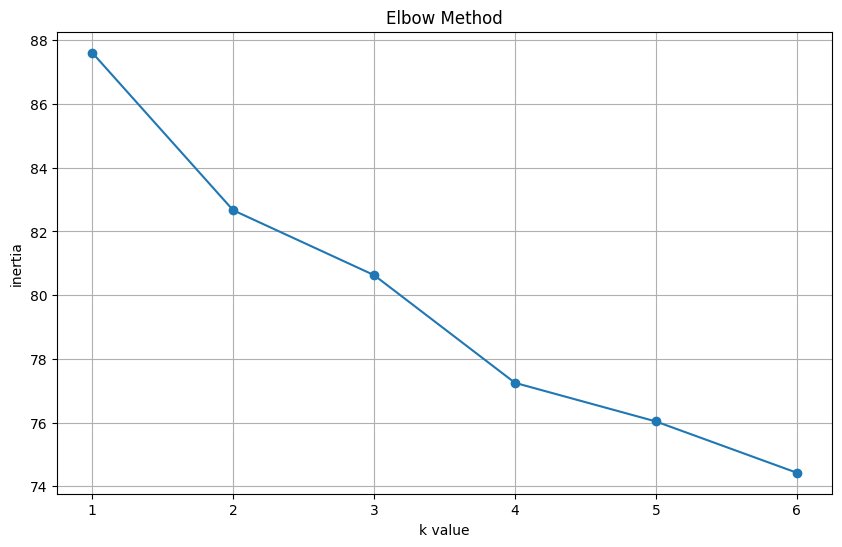

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.title('Elbow Method')
plt.grid()
plt.show()

In [ ]:
n_clusters = 4

In [ ]:
kM = KMeans(
    n_clusters=n_clusters,
    random_state=10,
    n_init=10
).fit(df_FE)

kM

KMeans(n_clusters=4, n_init=10, random_state=10)

In [ ]:
df_fe['Kmeans_label'] = kM.labels_

display(df_fe.head())

,text,prepro,Kmeans_label
0,Payah ngga ada dabunya😮😮😮,payah dabunya😮😮😮,0
1,Daging apa sih.,daging sih,1
2,bang traktir makan dong,bang traktir makan,2
3,Hidup MBG,hidup mbg,0
4,bagi lah bang boykun,bang boykun,2


In [ ]:
from sklearn import metrics

labels = kM.labels_

silhouette_kmeans = metrics.silhouette_score(
    df_FE,
    labels,
    metric='euclidean'
)

print("K-Means Silhouette Score:", silhouette_kmeans)

K-Means Silhouette Score: 0.060492323144752475


Kmeans for cluster 0


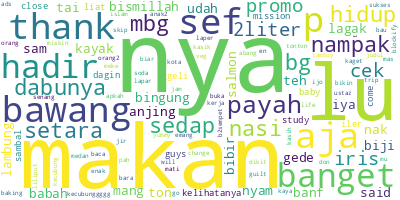

In [ ]:
c = 0

print('Kmeans for cluster ' + str(c))

df_c = df_fe[
    df_fe['Kmeans_label'] == c
]

long_string = ','.join(
    list(df_c['prepro'].values)
)

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


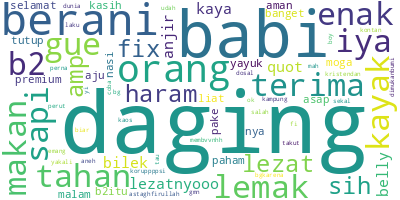

In [ ]:
c = 1

print('Kmeans for cluster ' + str(c))

df_c = df_fe[
    df_fe['Kmeans_label'] == c
]

long_string = ','.join(
    list(df_c['prepro'].values)
)

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


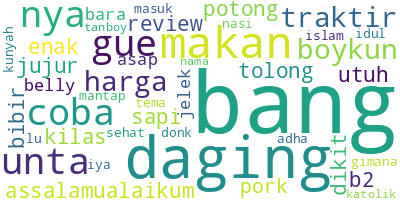

In [ ]:
c = 2

print('Kmeans for cluster ' + str(c))

df_c = df_fe[
    df_fe['Kmeans_label'] == c
]

long_string = ','.join(
    list(df_c['prepro'].values)
)

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 3


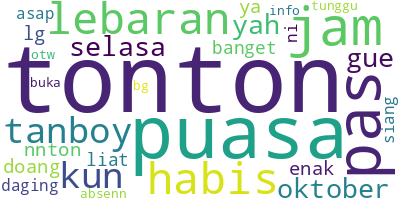

In [ ]:
c = 3

print('Kmeans for cluster ' + str(c))

df_c = df_fe[
    df_fe['Kmeans_label'] == c
]

long_string = ','.join(
    list(df_c['prepro'].values)
)

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

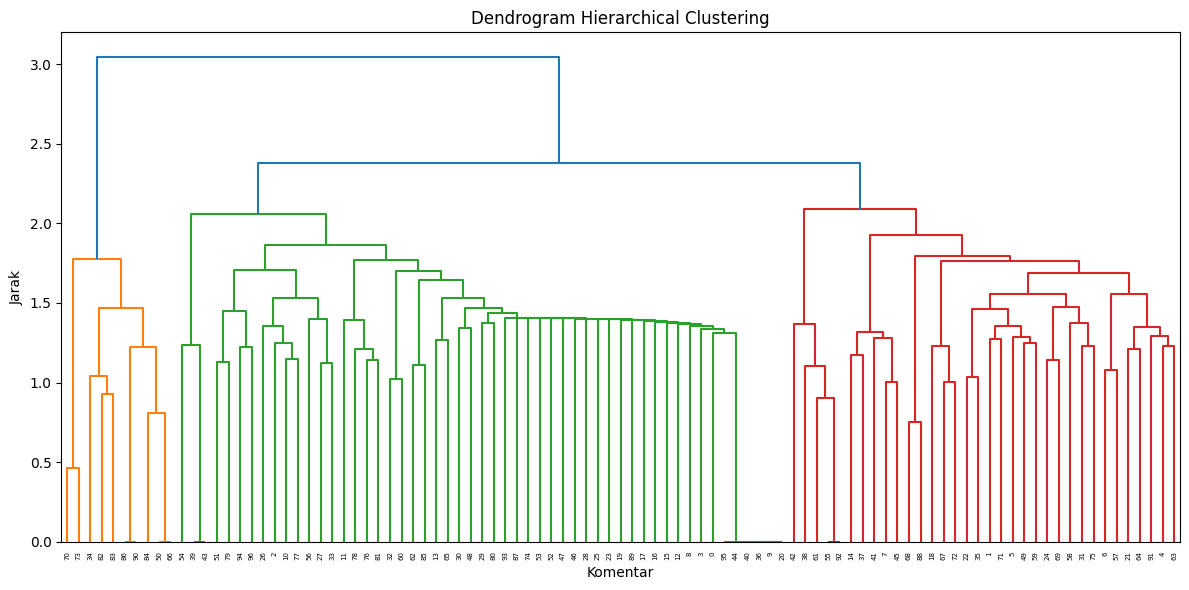

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

jumlah_hierarki = min(500, len(df_FE))

df_FE_hierarki = df_FE.iloc[:jumlah_hierarki]

linkage_data = linkage(
    df_FE_hierarki,
    method='ward',
    metric='euclidean'
)

plt.figure(figsize=(12, 6))
dendrogram(linkage_data)
plt.title('Dendrogram Hierarchical Clustering')
plt.xlabel('Komentar')
plt.ylabel('Jarak')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_cluster = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward'
)

labels_hierarchical = hierarchical_cluster.fit_predict(
    df_FE_hierarki
)

df_hierarchical = df_fe.iloc[:jumlah_hierarki].copy()

df_hierarchical['Ward_label'] = labels_hierarchical

display(df_hierarchical.head())

,text,prepro,Kmeans_label,Ward_label
0,Payah ngga ada dabunya😮😮😮,payah dabunya😮😮😮,0,0
1,Daging apa sih.,daging sih,1,2
2,bang traktir makan dong,bang traktir makan,2,0
3,Hidup MBG,hidup mbg,0,0
4,bagi lah bang boykun,bang boykun,2,2


In [ ]:
from sklearn import metrics

silhouette_hierarchical = metrics.silhouette_score(
    df_FE_hierarki,
    labels_hierarchical,
    metric='euclidean'
)

print(
    "Hierarchical Silhouette Score:",
    silhouette_hierarchical
)

Hierarchical Silhouette Score: 0.05038550077453544


Hierarchical for cluster 0


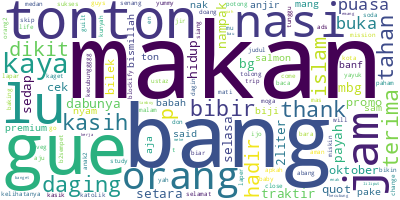

In [ ]:
c = 0

print('Hierarchical for cluster ' + str(c))

df_c = df_hierarchical[
    df_hierarchical['Ward_label'] == c
]

long_string = ','.join(
    list(df_c['prepro'].values)
)

wordcloud = WordCloud(
    background_color="white",
    max_words=5000,
    contour_width=3
)

wordcloud.generate(long_string)
wordcloud.to_image()

In [ ]:
print("Jumlah komentar pada K-Means:")
display(
    df_fe['Kmeans_label'].value_counts().sort_index()
)

print("Jumlah komentar pada Hierarchical:")
display(
    df_hierarchical['Ward_label'].value_counts().sort_index()
)

Jumlah komentar pada K-Means:


,count
Kmeans_label,
0,45
1,20
2,16
3,16


Jumlah komentar pada Hierarchical:


,count
Ward_label,
0,53
1,10
2,29
3,5
